 **Manisha Nacharam**

# **Waste Material Segregation for Improving Waste Management**

**Objective**

The objective of this project is to implement an effective waste material segregation system using convolutional neural networks (CNNs) that categorises waste into distinct groups. This process enhances recycling efficiency, minimises environmental pollution, and promotes sustainable waste management practices.

The key goals are:

Accurately classify waste materials into categories like cardboard, glass, paper, and plastic.
Improve waste segregation efficiency to support recycling and reduce landfill waste.
Understand the properties of different waste materials to optimise sorting methods for sustainability.

**Data Understanding**

The Dataset consists of images of some common waste materials.

Food Waste
Metal
Paper
Plastic
Other
Cardboard
Glass

**Data Description**

The dataset consists of multiple folders, each representing a specific class, such as Cardboard, Food_Waste, and Metal.
Within each folder, there are images of objects that belong to that category.
However, these items are not further subcategorised.
For instance, the Food_Waste folder may contain images of items like coffee grounds, teabags, and fruit peels, without explicitly stating that they are actually coffee grounds or teabags.

**1. Load the data**

Load and unzip the dataset zip file.

Import Necessary Libraries

In [34]:
# Recommended versions:

# numpy version: 1.26.4
# pandas version: 2.2.2
# seaborn version: 0.13.2
# matplotlib version: 3.10.0
# PIL version: 11.1.0
# tensorflow version: 2.18.0
# keras version: 3.8.0
# sklearn version: 1.6.1

In [35]:
# Import essential libraries

In [5]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

**Load the dataset.**

In [37]:
# Load and unzip the dataset

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

folder_path = '/content/drive/MyDrive/CNN_assignment'

print(os.listdir(folder_path))

['CNN_Assg_Waste_Segregation_Starter.ipynb', 'CNN_Ass_Waste_Segregation.pdf', 'data.zip']


In [8]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/CNN_assignment/data.zip'
extract_path = '/content/waste_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [9]:
dataset_path = '/content/waste_dataset/data'

print(os.listdir(dataset_path))

['Plastic', 'Glass', 'Cardboard', 'Paper', 'Metal', 'Other', 'Food_Waste']


**2. Data Preparation [25 marks]**


**2.1 Load and Preprocess Images [8 marks]**

Let us create a function to load the images first. We can then directly use this function while loading images of the different categories to load and crop them in a single step.

2.1.1 [3 marks]

Create a function to load the images. **bold text**

In [42]:
# Create a function to load the raw images

In [10]:
def load_images(dataset_path):
    images = []
    labels = []

    for class_name in os.listdir(dataset_path):
        class_path = os.path.join(dataset_path, class_name)

        if os.path.isdir(class_path):
            for image_name in os.listdir(class_path):
                image_path = os.path.join(class_path, image_name)

                try:
                    image = Image.open(image_path)
                    images.append(image.copy())
                    labels.append(class_name)
                    image.close()
                except:
                    pass

    return images, labels

2.1.2 [5 marks]

Load images and labels.

Load the images from the dataset directory. Labels of images are present in the subdirectories.

Verify if the images and labels are loaded correctly.

In [44]:
# Get the images and their labels

In [11]:
images, labels = load_images(dataset_path)

print("Number of images:", len(images))
print("Number of labels:", len(labels))

Number of images: 7625
Number of labels: 7625


In [12]:
print("First image size:", images[0].size)
print("First image label:", labels[0])
print("First 10 labels:", labels[:10])

First image size: (256, 256)
First image label: Plastic
First 10 labels: ['Plastic', 'Plastic', 'Plastic', 'Plastic', 'Plastic', 'Plastic', 'Plastic', 'Plastic', 'Plastic', 'Plastic']


Perform any operations, if needed, on the images and labels to get them into the desired format.

**2.2 Data Visualisation [9 marks]**

**2.2.1 [3 marks]**

Create a bar plot to display the class distribution

In [47]:
# Visualise Data Distribution

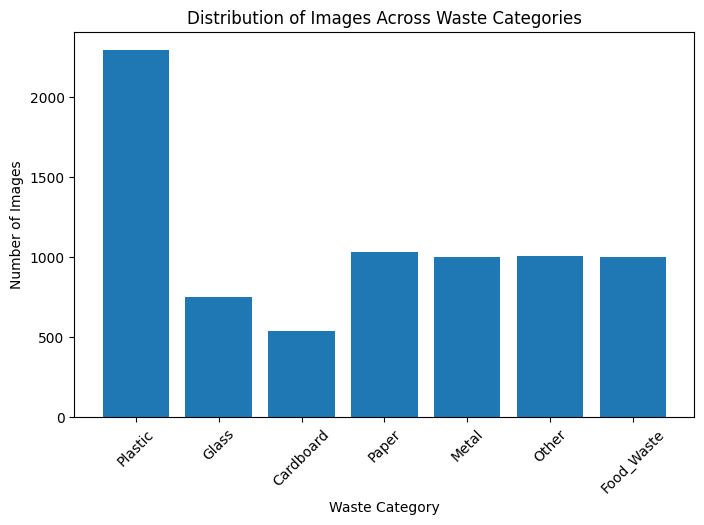

In [13]:
from collections import Counter
import matplotlib.pyplot as plt

class_counts = Counter(labels)

plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values())

plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.title("Distribution of Images Across Waste Categories")
plt.xticks(rotation=45)
plt.show()

**2.2.2 [3 marks]**

Visualise some sample images

In [49]:
# Visualise Sample Images (across different labels)

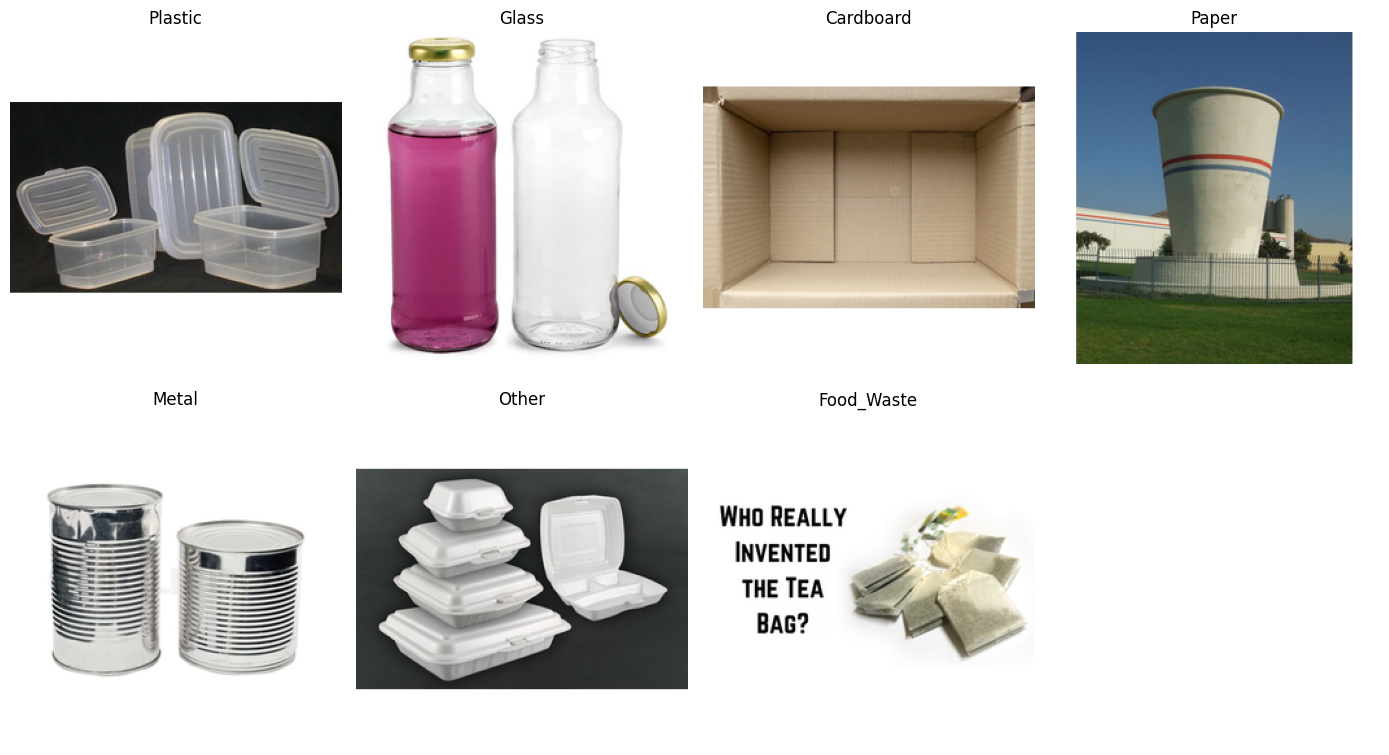

In [14]:
plt.figure(figsize=(14, 8))

classes = list(class_counts.keys())

for i, class_name in enumerate(classes):
    class_indices = [j for j, label in enumerate(labels) if label == class_name]

    sample_index = class_indices[0]

    plt.subplot(2, 4, i + 1)
    plt.imshow(images[sample_index])
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

Assumptions

- The folder names in the dataset were treated as the correct class labels.
- Images that could be opened successfully were used for analysis and model training.
- The dataset was split using a stratified 70:15:15 train-validation-test split to maintain class proportions.
- All images were resized from 256 × 256 pixels to 128 × 128 pixels for CNN training.

**2.2.3 [3 marks]**

Based on the smallest and largest image dimensions, resize the images.

In [51]:
# Find the smallest and largest image dimensions from the data set

In [15]:
widths = [img.size[0] for img in images]
heights = [img.size[1] for img in images]

print("Smallest width:", min(widths))
print("Largest width:", max(widths))
print("Smallest height:", min(heights))
print("Largest height:", max(heights))

Smallest width: 256
Largest width: 256
Smallest height: 256
Largest height: 256


In [53]:
# Resize the image dimensions

In [16]:
IMG_SIZE = (128, 128)

resized_images = [img.resize(IMG_SIZE) for img in images]

print("Original size:", images[0].size)
print("Resized size:", resized_images[0].size)

Original size: (256, 256)
Resized size: (128, 128)


**2.3 Encoding the classes [3 marks]**

**2.3.1 [3 marks]**

Encode the target class labels.

In [55]:
# Encode the labels suitably

In [17]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(labels)

print("Classes:", label_encoder.classes_)
print("First 10 encoded labels:", encoded_labels[:10])

Classes: ['Cardboard' 'Food_Waste' 'Glass' 'Metal' 'Other' 'Paper' 'Plastic']
First 10 encoded labels: [6 6 6 6 6 6 6 6 6 6]


**2.4 Data Splitting [5 marks]**

**2.4.1 [5 marks]**

Split the dataset into training and validation sets

In [57]:
# Assign specified parts of the dataset to train and validation sets

In [18]:
image_array = np.array([np.array(img) for img in resized_images])

print("Image array shape:", image_array.shape)
print("Labels shape:", encoded_labels.shape)

Image array shape: (7625, 128, 128, 3)
Labels shape: (7625,)


In [19]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_array,
    encoded_labels,
    test_size=0.30,
    random_state=42,
    stratify=encoded_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (5337, 128, 128, 3) (5337,)
Validation: (1144, 128, 128, 3) (1144,)
Test: (1144, 128, 128, 3) (1144,)


**3. Model Building and Evaluation [20 marks]**

**3.1 Model building and training [15 marks]**

**3.1.1 [10 marks]**

Build and compile the model. Use 3 convolutional layers. Add suitable normalisation, dropout, and fully connected layers to the model.

Test out different configurations and report the results in conclusions.

In [60]:
# Build and compile the model

In [20]:
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [21]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [22]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Dropout and Fully Connected Layers
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output layer - 7 waste categories
    layers.Dense(7, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,439 (12.61 MB)

 Trainable params: 3,305,991 (12.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [24]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


**3.1.2 [5 marks]**

Train the model.

Use appropriate metrics and callbacks as needed.

In [65]:
# Training

In [26]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 290s 2s/step - accuracy: 0.3955 - loss: 1.5492 - val_accuracy: 0.3785 - val_loss: 2.0175
Epoch 2/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.4019 - loss: 1.5480 - val_accuracy: 0.4003 - val_loss: 1.5645
Epoch 3/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 273s 2s/step - accuracy: 0.3991 - loss: 1.5375 - val_accuracy: 0.3689 - val_loss: 2.9213
Epoch 4/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.4103 - loss: 1.4989 - val_accuracy: 0.3776 - val_loss: 1.6768
Epoch 5/15
167/167 ━━━━━━━━━━━━━━━━━━━━ 280s 2s/step - accuracy: 0.4244 - loss: 1.4829 - val_accuracy: 0.3925 - val_loss: 1.5849


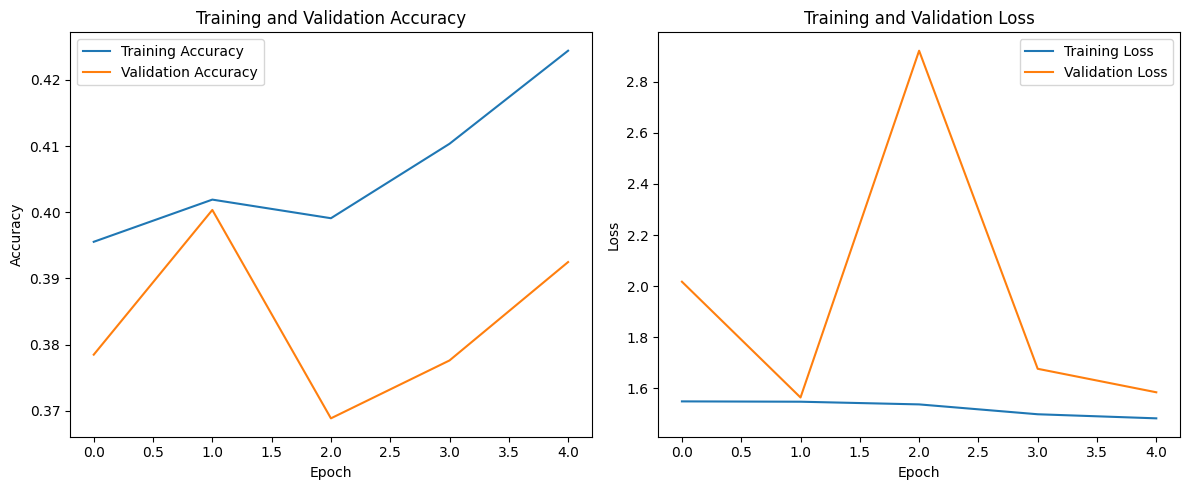

In [27]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

**3.2 Model Testing and Evaluation [5 marks]**

**3.2.1 [5 marks]**

Evaluate the model on test dataset. Derive appropriate metrics.

In [ ]:
# Evaluate on the test set; display suitable metrics


In [28]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

36/36 ━━━━━━━━━━━━━━━━━━━━ 12s 341ms/step - accuracy: 0.3995 - loss: 1.5806
Test Loss: 1.5806128978729248
Test Accuracy: 0.3994755148887634


In [29]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("Predictions generated:", len(y_pred))

36/36 ━━━━━━━━━━━━━━━━━━━━ 14s 373ms/step
Predictions generated: 1144


In [30]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

   Cardboard       0.00      0.00      0.00        81
  Food_Waste       0.28      0.71      0.40       150
       Glass       0.80      0.11      0.19       113
       Metal       0.00      0.00      0.00       150
       Other       0.72      0.09      0.15       151
       Paper       0.35      0.35      0.35       155
     Plastic       0.47      0.79      0.59       344

    accuracy                           0.40      1144
   macro avg       0.38      0.29      0.24      1144
weighted avg       0.40      0.40      0.32      1144



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


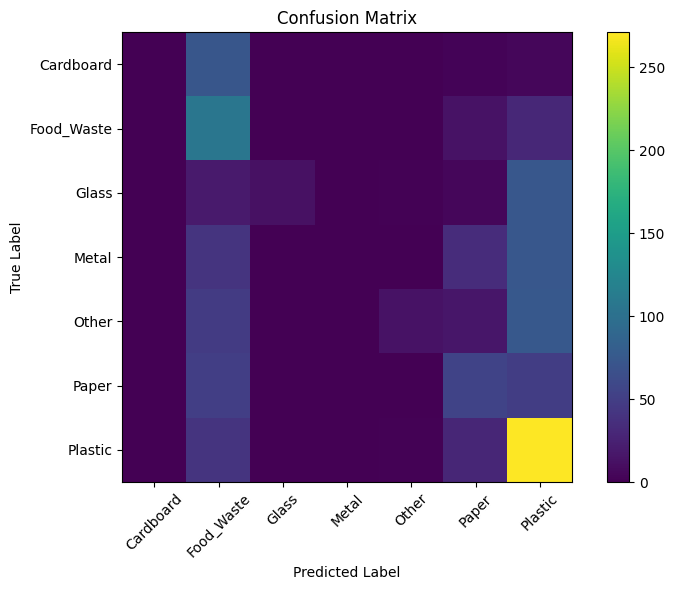

In [31]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.colorbar()

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=45
)
plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

**4. Data Augmentation [optional]**

**4.1 Create a Data Augmentation Pipeline**

4.1.1

Define augmentation steps for the datasets. **bold text**

In [ ]:
# Define augmentation steps to augment images

In [32]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


Augment and resample the images. In case of class imbalance, you can also perform adequate undersampling on the majority class and augment those images to ensure consistency in the input datasets for both classes.



Augment the images.

In [ ]:
# Create a function to augment the images

In [34]:
def augment_image(image, label):
    augmented_image = data_augmentation(image, training=True)
    return augmented_image, label

print("Augmentation function created.")

Augmentation function created.


In [ ]:
# Create the augmented training dataset

In [35]:
batch_size = 32

train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_dataset = train_dataset.shuffle(len(X_train))
train_dataset = train_dataset.batch(batch_size)

train_dataset = train_dataset.map(
    lambda x, y: (data_augmentation(x, training=True), y)
)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

print("Augmented training dataset created.")

Augmented training dataset created.


In [36]:
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))

train_dataset = train_dataset.shuffle(len(X_train))
train_dataset = train_dataset.batch(32)

train_dataset = train_dataset.map(
    augment_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

print("Augmented training dataset recreated successfully.")

Augmented training dataset recreated successfully.


4.1.2

Train the model on the new augmented dataset. **bold text**

In [ ]:
# Train the model using augmented images

In [37]:
history_aug = model.fit(
    train_dataset,
    validation_data=(X_val, y_val),
    epochs=10,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - accuracy: 0.3348 - loss: 1.7254 - val_accuracy: 0.3785 - val_loss: 1.8638
Epoch 2/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 321s 2s/step - accuracy: 0.3498 - loss: 1.6974 - val_accuracy: 0.3776 - val_loss: 1.6637
Epoch 3/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 298s 2s/step - accuracy: 0.3511 - loss: 1.6857 - val_accuracy: 0.3680 - val_loss: 2.1813


In [38]:
test_loss_aug, test_accuracy_aug = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Augmented Test Loss:", test_loss_aug)
print("Augmented Test Accuracy:", test_accuracy_aug)

36/36 ━━━━━━━━━━━━━━━━━━━━ 15s 413ms/step - accuracy: 0.3802 - loss: 1.9240
Augmented Test Loss: 1.9240370988845825
Augmented Test Accuracy: 0.38024476170539856


In [39]:
y_pred_probs_aug = model.predict(X_test)
y_pred_aug = np.argmax(y_pred_probs_aug, axis=1)

print("Augmented-model predictions generated:", len(y_pred_aug))

36/36 ━━━━━━━━━━━━━━━━━━━━ 15s 404ms/step
Augmented-model predictions generated: 1144


In [40]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_aug,
    target_names=label_encoder.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

   Cardboard       0.75      0.07      0.13        81
  Food_Waste       0.33      0.35      0.34       150
       Glass       1.00      0.04      0.08       113
       Metal       0.00      0.00      0.00       150
       Other       1.00      0.01      0.01       151
       Paper       0.59      0.26      0.36       155
     Plastic       0.37      0.96      0.53       344

    accuracy                           0.38      1144
   macro avg       0.58      0.24      0.21      1144
weighted avg       0.52      0.38      0.27      1144



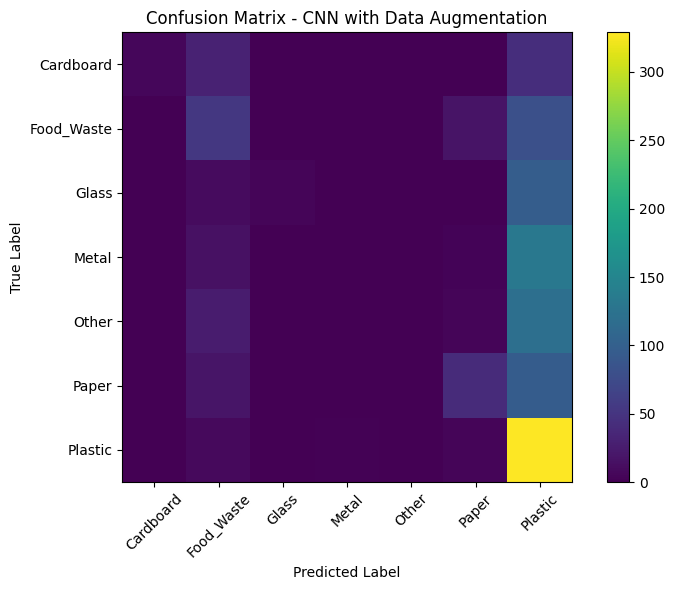

In [41]:
cm_aug = confusion_matrix(y_test, y_pred_aug)

plt.figure(figsize=(8, 6))
plt.imshow(cm_aug)
plt.colorbar()

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=45
)
plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - CNN with Data Augmentation")

plt.tight_layout()
plt.show()

**5. Conclusions [5 marks]**

**5.1 Conclude with outcomes and insights gained [5 marks]**

 Conclusion and Key Takeaways

- The dataset contains 7,625 images belonging to 7 waste categories: Cardboard, Food_Waste, Glass, Metal, Other, Paper, and Plastic.
- The dataset is imbalanced, with Plastic having the highest number of images and Cardboard having the lowest.
- All images had the same original dimensions of 256 × 256 pixels, so they were resized to 128 × 128 pixels for CNN training.
- The data was divided into training, validation, and test sets using a stratified split.
- A CNN with three convolutional layers, batch normalization, dropout, and fully connected layers was developed for waste classification.
- The initial CNN achieved a test accuracy of approximately 39.95%.
- Continued training with data augmentation resulted in a test accuracy of approximately 38.02%. In this experiment, data augmentation did not improve the test accuracy compared with the initial CNN.
- The classification results show that Plastic was recognized better than most other classes, while several classes had low recall and were frequently confused with other categories.
- The main limitation was the class imbalance and difficulty in distinguishing visually similar waste categories.
- Overall, the CNN demonstrated the potential for automated waste classification, but further improvements such as better class balancing, additional training, and more suitable model configurations could improve classification performance.

Report your findings about the data
Report model training results

->The dataset contains 7,625 images from 7 waste categories: Cardboard, Food_Waste, Glass, Metal, Other, Paper, and Plastic. The class distribution is imbalanced, with Plastic having the highest number of images (2,295) and Cardboard having the lowest (540). All images were originally 256 × 256 pixels, so they were resized to 128 × 128 pixels before training. The data was divided into training, validation, and test sets using a stratified split.

-> A CNN with three convolutional layers, batch normalization, dropout, and fully connected layers was trained for waste classification. The initial CNN achieved a test accuracy of 39.95%. Data augmentation was then used for continued training, after which the test accuracy was 38.02%. The classification report and confusion matrix show that Plastic was recognized better than several other classes, while some classes had difficulty being correctly identified. This indicates that further improvements in class balancing and model configuration could improve the results.
